<b>Brain Tumor Case Study</b>
<p><b>Priyanka Saha, Jennifer Steiner</p>
<p>MSDS621</p>

This notebook is for the Case Study chosen by Priyanka Saha and Jennifer Steiner for Regis University, MSDS 621, Fall 8 week 2.
<p>The code will process a UNet LLM, then accept outside images to determine if a tumor is present</p>
<p>Data set images were taken from https://www.kaggle.com/datasets/mateuszbuda/lgg-mri-segmentation/data</p>

In [1]:
#bring in packages needed 
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
import shutil
from pathlib import Path
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"
#set the images size and the path where the images live

img_size=(256,256)
im_width=256 
im_height=256
dataset_root='C:/Users/jenni/Documents/MSDS/MSDS621/'
dataset_path = dataset_root+'lgg-mri-segmentation/'
dataset_new_path=dataset_root+'new_image'


Review the data csv that was present with the images


In [2]:
df_braindata = pd.read_csv(dataset_path+'kaggle_3m/data.csv')
print(df_braindata.head()) 

        Patient  RNASeqCluster  MethylationCluster  miRNACluster  CNCluster  \
0  TCGA_CS_4941            2.0                 4.0             2        2.0   
1  TCGA_CS_4942            1.0                 5.0             2        1.0   
2  TCGA_CS_4943            1.0                 5.0             2        1.0   
3  TCGA_CS_4944            NaN                 5.0             2        1.0   
4  TCGA_CS_5393            4.0                 5.0             2        1.0   

   RPPACluster  OncosignCluster  COCCluster  histological_type  \
0          NaN              3.0           2                1.0   
1          1.0              2.0           1                1.0   
2          2.0              2.0           1                1.0   
3          2.0              1.0           1                1.0   
4          2.0              3.0           1                1.0   

   neoplasm_histologic_grade  tumor_tissue_site  laterality  tumor_location  \
0                        2.0                1.0  

In [3]:
df_braindata.info()

<class 'pandas.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Patient                    110 non-null    str    
 1   RNASeqCluster              92 non-null     float64
 2   MethylationCluster         109 non-null    float64
 3   miRNACluster               110 non-null    int64  
 4   CNCluster                  108 non-null    float64
 5   RPPACluster                98 non-null     float64
 6   OncosignCluster            105 non-null    float64
 7   COCCluster                 110 non-null    int64  
 8   histological_type          109 non-null    float64
 9   neoplasm_histologic_grade  109 non-null    float64
 10  tumor_tissue_site          109 non-null    float64
 11  laterality                 109 non-null    float64
 12  tumor_location             109 non-null    float64
 13  gender                     109 non-null    float64
 14  age_a

The data file confirms that there are 110 patient entries.  The images files have been named with the following convention:
`TCGA_<institution-code>_<patient-id>_<slice-number>.tif` 
<br>  The images already have a corresponding _mask file, so it is not necessary to create new ones.


In [4]:
#establish a list for the image and mask path
image_paths = []
mask_paths = []

#add the image paths to the correct list.  Accommodate for tif, jpg, png
for dirpath, dirnames, filenames in os.walk(dataset_path):
    for filename in filenames:
        if 'mask' not in filename and filename.endswith('.tif'):
            image_paths.append(os.path.join(dirpath, filename))
            mask_paths.append(os.path.join(dirpath, filename.replace('.tif', '_mask.tif')))
        if 'mask' not in filename and filename.endswith('.jpg'):
            image_paths.append(os.path.join(dirpath, filename))
            mask_paths.append(os.path.join(dirpath, filename.replace('.jpg', '_mask.jpg')))
        if 'mask' not in filename and filename.endswith('.png'):
            image_paths.append(os.path.join(dirpath, filename))
            mask_paths.append(os.path.join(dirpath, filename.replace('.png', '_mask.png')))

#set up dataframe with the image paths
#add patient to the dataframe so it can be matched to the data.csv

df = pd.DataFrame(data={'image_path': image_paths, 'mask_path': mask_paths})
#create a csv for the path of each image
df['Patient'] = df['image_path'].apply(lambda x: Path(x).stem)
df['Patient']=df['Patient'].str[0:12]
df.to_csv(dataset_path+"brain_images.csv", index=False)

# Train, Validation, Test
train_df, test_df = train_test_split(df, test_size=0.1)
train_df, val_df = train_test_split(train_df, test_size=0.15)

print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Train: 3005, Val: 531, Test: 393


In [5]:
df_brainpath = pd.read_csv(dataset_path+'/brain_images.csv')
df_brainpath.head()

,image_path,mask_path,Patient
0,C:/Users/jenni/Documents/MSDS/MSDS621/lgg-mri-...,C:/Users/jenni/Documents/MSDS/MSDS621/lgg-mri-...,TCGA_CS_4941
1,C:/Users/jenni/Documents/MSDS/MSDS621/lgg-mri-...,C:/Users/jenni/Documents/MSDS/MSDS621/lgg-mri-...,TCGA_CS_4941
2,C:/Users/jenni/Documents/MSDS/MSDS621/lgg-mri-...,C:/Users/jenni/Documents/MSDS/MSDS621/lgg-mri-...,TCGA_CS_4941
3,C:/Users/jenni/Documents/MSDS/MSDS621/lgg-mri-...,C:/Users/jenni/Documents/MSDS/MSDS621/lgg-mri-...,TCGA_CS_4941
4,C:/Users/jenni/Documents/MSDS/MSDS621/lgg-mri-...,C:/Users/jenni/Documents/MSDS/MSDS621/lgg-mri-...,TCGA_CS_4941


In [6]:
df_brainpath.info()

<class 'pandas.DataFrame'>
RangeIndex: 3929 entries, 0 to 3928
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   image_path  3929 non-null   str  
 1   mask_path   3929 non-null   str  
 2   Patient     3929 non-null   str  
dtypes: str(3)
memory usage: 1.0 MB


The path csv confirms there are 3929 images that will be used in the train, test, validation process

In [7]:
#create the data generator for the model
#include the resizing of images
def data_generator(data_frame, batch_size=16):
    while True:
        for i in range(0, len(data_frame), batch_size):
            batch_df = data_frame[i:i+batch_size]
            images = []
            masks = []
            
            for index, row in batch_df.iterrows():
               
                img = cv2.imread(row['image_path'])
                img = cv2.resize(img, (im_width, im_height))
                img = img / 255.0  # Normalization
                
            
                mask = cv2.imread(row['mask_path'], cv2.IMREAD_GRAYSCALE)
                mask = cv2.resize(mask, (im_width, im_height))
                mask = mask / 255.0
                mask = np.expand_dims(mask, axis=-1) # (256, 256, 1)
                
                images.append(img)
                masks.append(mask)
                
            yield np.array(images), np.array(masks)

In [8]:
from tensorflow.keras import backend as K

# (Fixed Metrics) ---
#the dice coefficient--measures how similar or overlapping two sets or regions are, returning a value from 0 (no overlap) to 1 (identical / complete overlap).
def dice_coef(y_true, y_pred, smooth=1):
    
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

#the iou coefficient--measures how much two regions or sets overlap
def iou_coef(y_true, y_pred, smooth=1):
    
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    
    intersection = K.sum(K.abs(y_true * y_pred), axis=[1,2,3])
    union = K.sum(y_true,[1,2,3])+K.sum(y_pred,[1,2,3])-intersection
    return K.mean((intersection + smooth) / (union + smooth), axis=0)

# --- 2. (Model Architecture) ---
def unet_model(input_size=(256, 256, 3)):
    inputs = Input(input_size)
    
    # Encoder
    conv1 = Conv2D(64, 3, activation='relu', padding='same')(inputs)
    conv1 = Conv2D(64, 3, activation='relu', padding='same')(conv1)
    pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)

    conv2 = Conv2D(128, 3, activation='relu', padding='same')(pool1)
    conv2 = Conv2D(128, 3, activation='relu', padding='same')(conv2)
    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)

    conv3 = Conv2D(256, 3, activation='relu', padding='same')(pool2)
    conv3 = Conv2D(256, 3, activation='relu', padding='same')(conv3)
    pool3 = MaxPooling2D(pool_size=(2, 2))(conv3)

    # Bottleneck
    conv4 = Conv2D(512, 3, activation='relu', padding='same')(pool3)
    conv4 = Conv2D(512, 3, activation='relu', padding='same')(conv4)
    drop4 = Dropout(0.5)(conv4)

    # Decoder
    up5 = UpSampling2D(size=(2, 2))(drop4)
    up5 = Conv2D(256, 2, activation='relu', padding='same')(up5)
    merge5 = concatenate([conv3, up5], axis=3)
    conv5 = Conv2D(256, 3, activation='relu', padding='same')(merge5)
    conv5 = Conv2D(256, 3, activation='relu', padding='same')(conv5)

    up6 = UpSampling2D(size=(2, 2))(conv5)
    up6 = Conv2D(128, 2, activation='relu', padding='same')(up6)
    merge6 = concatenate([conv2, up6], axis=3)
    conv6 = Conv2D(128, 3, activation='relu', padding='same')(merge6)
    conv6 = Conv2D(128, 3, activation='relu', padding='same')(conv6)

    up7 = UpSampling2D(size=(2, 2))(conv6)
    up7 = Conv2D(64, 2, activation='relu', padding='same')(up7)
    merge7 = concatenate([conv1, up7], axis=3)
    conv7 = Conv2D(64, 3, activation='relu', padding='same')(merge7)
    conv7 = Conv2D(64, 3, activation='relu', padding='same')(conv7)

    # Output Layer
    conv8 = Conv2D(1, 1, activation='sigmoid')(conv7)

    model = Model(inputs=inputs, outputs=conv8)
    return model

# --- 3.(Compile) ---
model = unet_model()
# learning_rate 

model.compile(optimizer=Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=[dice_coef, iou_coef])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 256, 256, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 256, 256, 64)      │           1,792 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 256, 256, 64)      │          36,928 │ conv2d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 128, 128, 64)      │               0 │ conv2d_1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 128, 128, 128)     │          73,856 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 128, 128, 128)     │         147,584 │ conv2d_2[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_1               │ (None, 64, 64, 128)       │               0 │ conv2d_3[0][0]             │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 64, 64, 256)       │         295,168 │ max_pooling2d_1[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)             │ (None, 64, 64, 256)       │         590,080 │ conv2d_4[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_2               │ (None, 32, 32, 256)       │               0 │ conv2d_5[0][0]             │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_6 (Conv2D)             │ (None, 32, 32, 512)       │       1,180,160 │ max_pooling2d_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_7 (Conv2D)             │ (None, 32, 32, 512)       │       2,359,808 │ conv2d_6[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 32, 32, 512)       │               0 │ conv2d_7[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ up_sampling2d (UpSampling2D)  │ (None, 64, 64, 512)       │               0 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_8 (Conv2D)             │ (None, 64, 64, 256)       │         524,544 │ up_sampling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 64, 64, 512)       │               0 │ conv2d_5[0][0],            │
│                               │                           │               

 Total params: 7,697,345 (29.36 MB)

 Trainable params: 7,697,345 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
#set the batch size to 32, so it processes 32 images at a time
#this executes the model and will walk through 10 epochs.  
BATCH_SIZE = 32
SPE = len(train_df) // BATCH_SIZE # Steps Per Epoch

# Callbacks  Learning Rate
callbacks = [
    ModelCheckpoint('unet_brain_mri.keras', verbose=1, save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=5, verbose=1),
    EarlyStopping(monitor='val_loss', patience=10, verbose=1)
]

history = model.fit(
    data_generator(train_df, BATCH_SIZE),
    validation_data=data_generator(val_df, BATCH_SIZE),
    steps_per_epoch=SPE,
    validation_steps=len(val_df) // BATCH_SIZE,
    epochs=10, # epochs 
    callbacks=callbacks
)

C:\Users\jenni\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 16s/step - dice_coef: 0.0581 - iou_coef: 0.0158 - loss: 0.1469 
Epoch 1: val_loss improved from None to 0.03370, saving model to unet_brain_mri.keras

Epoch 1: finished saving model to unet_brain_mri.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 1560s 17s/step - dice_coef: 0.0581 - iou_coef: 0.0158 - loss: 0.1469 - val_dice_coef: 0.1687 - val_iou_coef: 0.0437 - val_loss: 0.0337 - learning_rate: 1.0000e-04
Epoch 2/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 16s/step - dice_coef: 0.2218 - iou_coef: 0.0636 - loss: 0.0298 
Epoch 2: val_loss improved from 0.03370 to 0.02878, saving model to unet_brain_mri.keras

Epoch 2: finished saving model to unet_brain_mri.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 1564s 17s/step - dice_coef: 0.2218 - iou_coef: 0.0636 - loss: 0.0298 - val_dice_coef: 0.2870 - val_iou_coef: 0.0820 - val_loss: 0.0288 - learning_rate: 1.0000e-04
Epoch 3/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 16s/step - dice_coef: 0.2899 - iou_coef: 0.0879 - loss: 0.0266 
Epoch 3: val_loss 

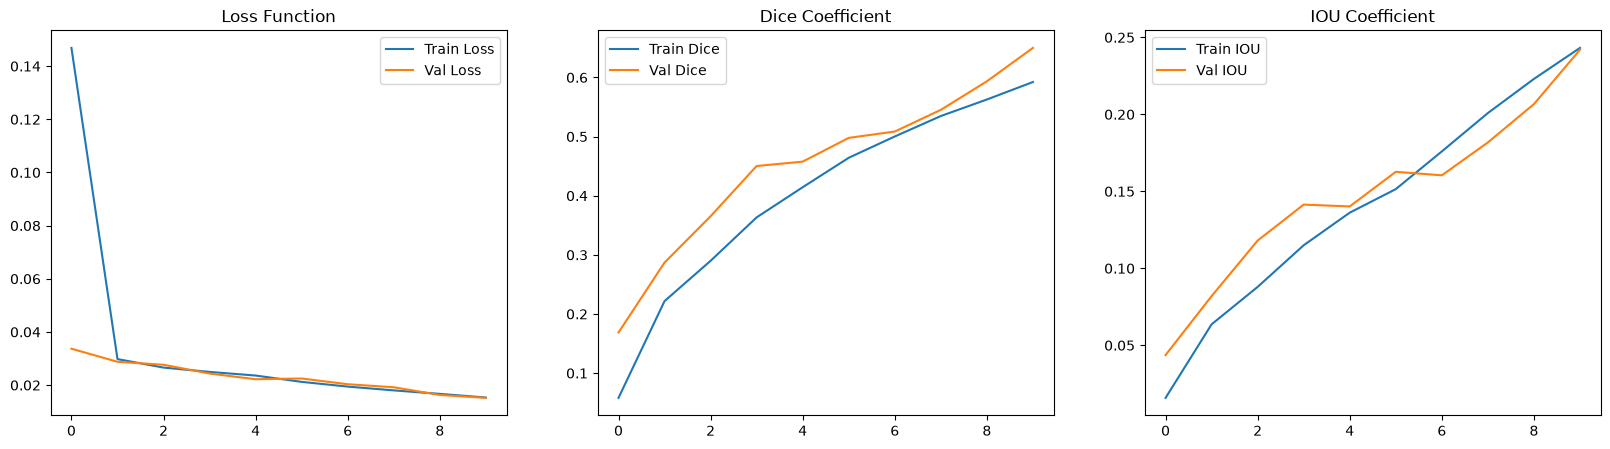

In [10]:
plt.figure(figsize=(20, 5))

# Plot Loss
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Function')
plt.legend()

# Plot Dice Coefficient
plt.subplot(1, 3, 2)
plt.plot(history.history['dice_coef'], label='Train Dice')
plt.plot(history.history['val_dice_coef'], label='Val Dice')
plt.title('Dice Coefficient')
plt.legend()

# Plot IOU
plt.subplot(1, 3, 3)
plt.plot(history.history['iou_coef'], label='Train IOU')
plt.plot(history.history['val_iou_coef'], label='Val IOU')
plt.title('IOU Coefficient')
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 709ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step


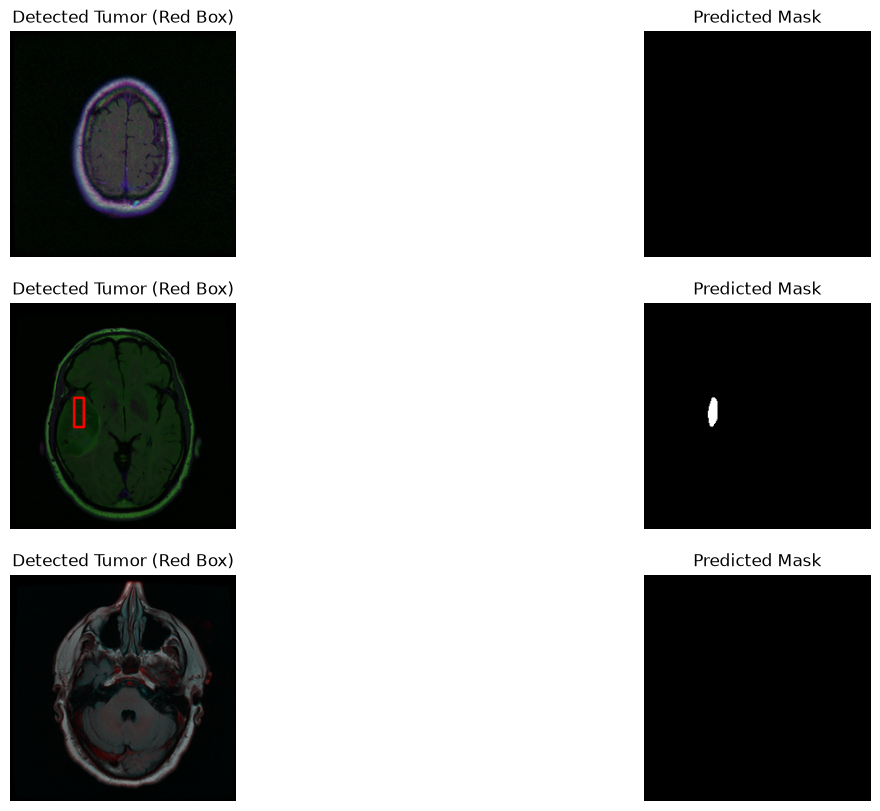

In [11]:
def predict_and_draw_bbox(row):
    img_path = row['image_path']
    img = cv2.imread(img_path)
    img = cv2.resize(img, (im_width, im_height))
    img_norm = img / 255.0
    img_input = np.expand_dims(img_norm, axis=0)
    
    # Segmentation)
    pred_mask = model.predict(img_input)
    pred_mask = (pred_mask > 0.5).astype(np.uint8)[0, :, :, 0] # Binary
    
    # إContours
    contours, _ = cv2.findContours(pred_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) 
    
    # (Bounding Box)
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w > 5 and h > 5: 
            cv2.rectangle(img_rgb, (x, y), (x+w, y+h), (255, 0, 0), 2) # RGB)
    
    return img_rgb, pred_mask

# Test Set
samples = test_df.sample(3)
plt.figure(figsize=(15, 10))

for i, (_, row) in enumerate(samples.iterrows()):
    result_img, result_mask = predict_and_draw_bbox(row)
    
    plt.subplot(3, 2, 2*i + 1)
    plt.imshow(result_img)
    plt.title("Detected Tumor (Red Box)")
    plt.axis('off')
    
    plt.subplot(3, 2, 2*i + 2)
    plt.imshow(result_mask, cmap='gray')
    plt.title("Predicted Mask")
    plt.axis('off')

plt.show()

In [14]:
image_path = []
mask_path = []

source_folder = Path(dataset_new_path)
dest_folder = Path(dataset_new_path)
#dest_folder.mkdir(exist_ok=True)  # Creates destination folder if it doesn't exist

suffix_to_append = "_mask"
valid_extensions = {".jpg", ".jpeg", ".png", ".webp",".tif"}

for file_path in source_folder.iterdir():
    if file_path.is_file() and 'mask' not in filename and  file_path.suffix.lower() in valid_extensions:
        new_name = f"{file_path.stem}{suffix_to_append}{file_path.suffix}"
        shutil.copy2(file_path, dest_folder / new_name)

for dirpath, dirnames, filenames in os.walk(dataset_new_path):
    for filename in filenames:
        if 'mask' not in filename and filename.endswith('.tif'):
            image_path.append(os.path.join(dirpath, filename))
            mask_path.append(os.path.join(dirpath, filename.replace('.tif', '_mask.tif')))
        if 'mask' not in filename and filename.endswith('.jpg'):
            image_path.append(os.path.join(dirpath, filename))
            mask_path.append(os.path.join(dirpath, filename.replace('.jpg', '_mask.jpg')))
        if 'mask' not in filename and filename.endswith('.png'):
            image_path.append(os.path.join(dirpath, filename))
            mask_path.append(os.path.join(dirpath, filename.replace('.png', '_mask.png')))

df1 = pd.DataFrame(data={'image_path': image_path, 'mask_path': mask_path})
df1.head()

,image_path,mask_path
0,C:/Users/jenni/Documents/MSDS/MSDS621/new_imag...,C:/Users/jenni/Documents/MSDS/MSDS621/new_imag...
1,C:/Users/jenni/Documents/MSDS/MSDS621/new_imag...,C:/Users/jenni/Documents/MSDS/MSDS621/new_imag...
2,C:/Users/jenni/Documents/MSDS/MSDS621/new_imag...,C:/Users/jenni/Documents/MSDS/MSDS621/new_imag...
3,C:/Users/jenni/Documents/MSDS/MSDS621/new_imag...,C:/Users/jenni/Documents/MSDS/MSDS621/new_imag...


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step


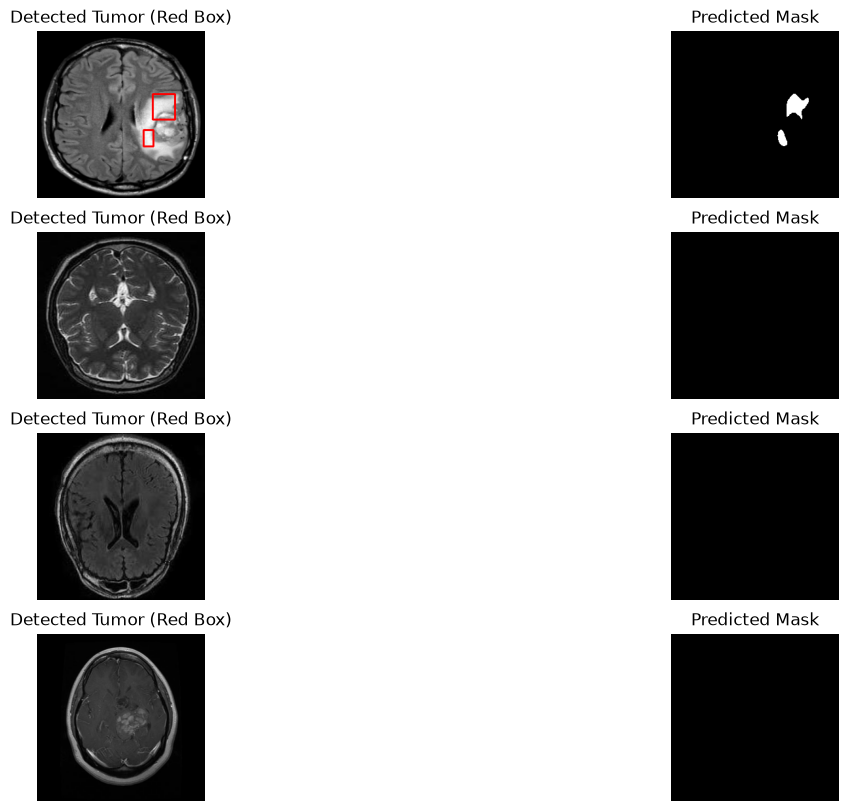

In [19]:
samples1 = df1.sample(4)
plt.figure(figsize=(15, 10))

for i, (_, row) in enumerate(samples1.iterrows()):
    result_img, result_mask = predict_and_draw_bbox(row)
    
    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(result_img)
    plt.title("Detected Tumor (Red Box)")
    plt.axis('off')
    
    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(result_mask, cmap='gray')
    plt.title("Predicted Mask")
    plt.axis('off')

plt.show()